# Phase 1 — Load & Explore (ULB Credit Card Fraud)

**Goal:** get a first look at the data *before* any modeling. Know the shape, quality, and — most importantly — how rare fraud is.

We import logic from `src/` rather than redefining it here. The notebook *tells the story*; the `src/` files do the work.

In [1]:
import sys
from pathlib import Path
# Make src/ importable from the notebook
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from src.data_loader import load_data, summarize, amount_by_class

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.4f}'.format)

In [2]:
# Load the data (expects data/raw/creditcard.csv — see README to download)
df = load_data()
df.head()

Loaded 284,807 rows x 31 columns
Fraud rate: 0.1727%  (492 fraud cases)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


## 1. First-look summary
Shape, missing values, duplicates, and class balance — the 'know your data' step.

In [3]:
summarize(df)

SHAPE: (284807, 31)

MISSING VALUES (non-zero only):
  None ✓



DUPLICATE ROWS: 1,081



CLASS BALANCE:
  0 (LEGIT):  284,315  (99.8273%)
  1 (FRAUD):      492  (0.1727%)


## 2. The imbalance problem, visualized
This chart is *why* accuracy is the wrong metric: a model that always predicts 'legit' would be ~99.8% accurate and catch zero fraud.

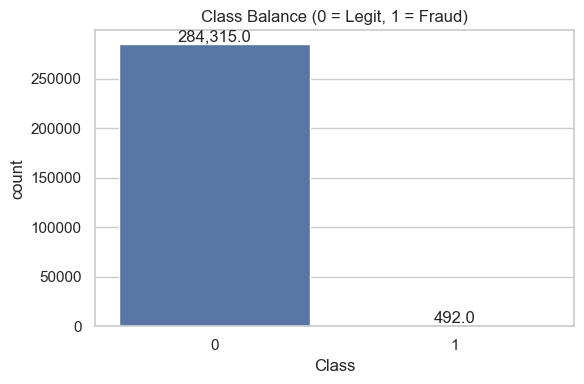

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Class', ax=ax)
ax.set_title('Class Balance (0 = Legit, 1 = Fraud)')
for p in ax.patches:
    ax.annotate(f'{p.get_height():,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()

## 3. Do frauds look different in size?
Our first business question. Note the log/clipped x-axis — without it a few huge transactions flatten everything.

            count     mean      std    min    25%     50%      75%        max
Class                                                                        
0     284315.0000  88.2910 250.1051 0.0000 5.6500 22.0000  77.0500 25691.1600
1        492.0000 122.2113 256.6833 0.0000 1.0000  9.2500 105.8900  2125.8700


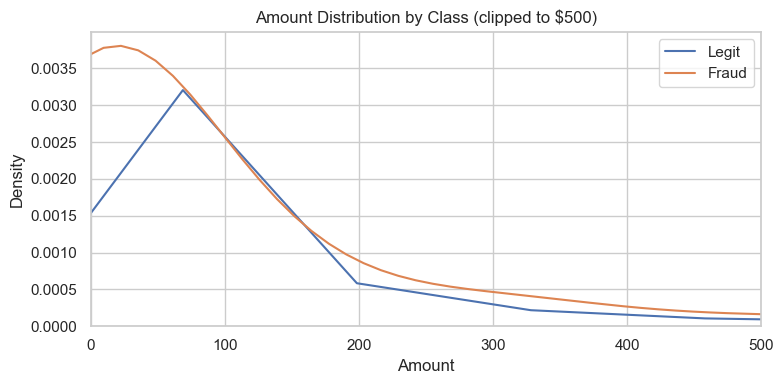

In [5]:
print(amount_by_class(df))

fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(data=df[df.Class==0], x='Amount', label='Legit', ax=ax)
sns.kdeplot(data=df[df.Class==1], x='Amount', label='Fraud', ax=ax)
ax.set_xlim(0, 500)  # clip — most transactions are small
ax.set_title('Amount Distribution by Class (clipped to $500)')
ax.legend()
plt.tight_layout()
plt.show()

## 📝 Phase 1 takeaways (fill in after running)
- Fraud rate: ____%
- Duplicates found: ____
- Does fraud differ by amount? ____

**Next — Phase 2:** clean (drop duplicates), scale `Amount`/`Time`, and split data *before* any resampling.